# 03 Customer segments (RFM)

**Goal:** group customers by how recently, how often and how much they buy, so a marketing team can target each group differently.
**Why:** only 3.1% of customers come back (EDA Q10), so retention is the biggest untapped lever.
**Data:** `orders_clean.parquet`, delivered orders only.

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

PROCESSED = r"..\data\processed"
FIG = r"..\reports\figures"

orders = pd.read_parquet(PROCESSED + r"\orders_clean.parquet")
delivered = orders[orders['order_delivered_customer_date'].notna()].copy()
print(delivered.shape)

(96476, 27)


## Step 1. What is RFM?
- **Recency:** days since the customer's last order (lower = better)
- **Frequency:** number of orders
- **Monetary:** total amount spent (BRL)

Reference date = the day after the last order in the data, so recency is measured from the end of the dataset.

In [2]:
ref_date = delivered['order_purchase_timestamp'].max() + pd.Timedelta(days=1)
ref_date

Timestamp('2018-08-30 15:00:37')

In [3]:
rfm = delivered.groupby('customer_unique_id').agg(
    last_order=('order_purchase_timestamp', 'max'),
    frequency=('order_id', 'count'),
    monetary=('total_paid', 'sum'),
)
rfm['recency'] = (ref_date - rfm['last_order']).dt.days
rfm.head()

,last_order,frequency,monetary,recency
customer_unique_id,,,,
0000366f3b9a7992bf8c76cfdf3221e2,2018-05-10 10:56:27,1,141.90,112
0000b849f77a49e4a4ce2b2a4ca5be3f,2018-05-07 11:11:27,1,27.19,115
0000f46a3911fa3c0805444483337064,2017-03-10 21:05:03,1,86.22,537
0000f6ccb0745a6a4b88665a16c9f078,2017-10-12 20:29:41,1,43.62,321
0004aac84e0df4da2b147fca70cf8255,2017-11-14 19:45:42,1,196.89,288


In [4]:
rfm[['recency', 'frequency', 'monetary']].describe().round(1)

,recency,frequency,monetary
count,93356.0,93356.0,93356.0
mean,238.0,1.0,165.2
std,152.6,0.2,226.3
min,1.0,1.0,0.0
25%,114.0,1.0,63.0
50%,219.0,1.0,107.8
75%,346.0,1.0,182.5
max,714.0,15.0,13664.1


**RFM summary:** 93,356 customers with a delivered order. The typical customer last bought 219 days (about 7 months) before the end of the data and spent 108 BRL in total (median). Almost all bought once: frequency is 1 for at least 75% of customers, so frequency cannot be scored in equal groups.

## Step 2. Score each customer
- Recency and monetary: 5 equal groups (1 = worst, 5 = best).
- Frequency: fixed groups, because almost everyone has 1 order: 1 order = 1, 2 orders = 2, 3+ orders = 3.

In [5]:
rfm['R'] = pd.qcut(rfm['recency'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm['M'] = pd.qcut(rfm['monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['F'] = pd.cut(rfm['frequency'], bins=[0, 1, 2, float('inf')], labels=[1, 2, 3]).astype(int)

rfm[['R', 'F', 'M']].apply(pd.Series.value_counts).sort_index()

,R,F,M
1,18643,90555.0,18675
2,18576,2573.0,18683
3,18710,228.0,18658
4,18705,NaN,18672
5,18722,NaN,18668


## Step 3. Name the segments
Each customer goes through a rulebook and lands in the first segment whose rule fits.

| Segment | Rule | Meaning |
| --- | --- | --- |
| Champions | 2+ orders, bought recently (R 4-5) | Best customers |
| Loyal, slipping | 2+ orders, not recently (R 1-3) | Came back before, worth a nudge |
| New, high value | 1 order, recent (R 4-5), big spend (M 4-5) | Turn into repeat buyers |
| New | 1 order, recent, smaller spend | Second purchase is the goal |
| At risk, high value | 1 order, a while ago (R 2-3), big spend (M 4-5) | Win back before they are lost |
| Hibernating | 1 order, a while ago, smaller spend | Low-cost reminders |
| Lost | 1 order, long ago (R 1) | Unlikely to return |

Rules are checked from top to bottom, so the order matters.

In [6]:
def segment(row):
    if row['F'] >= 2 and row['R'] >= 4:
        return 'Champions'
    if row['F'] >= 2:
        return 'Loyal, slipping'
    if row['R'] >= 4 and row['M'] >= 4:
        return 'New, high value'
    if row['R'] >= 4:
        return 'New'
    if row['R'] >= 2 and row['M'] >= 4:
        return 'At risk, high value'
    if row['R'] >= 2:
        return 'Hibernating'
    return 'Lost'

In [7]:
rfm['segment'] = rfm.apply(segment, axis=1)
rfm['segment'].value_counts()

segment
Hibernating            22261
New                    21776
Lost                   18208
New, high value        14442
At risk, high value    13868
Loyal, slipping         1592
Champions               1209
Name: count, dtype: int64

**Segment sizes:** The largest segment is **Hibernating** with **22,261** customers (24%), followed by New (21,776) and Lost (18,208).
Champions (**1,209**) and Loyal, slipping (**1,592**) add up to **2,801**, which matches the repeat buyers from step 2.
Only 3% of customers are in a repeat segment; 97% bought once.

**First campaign to run:** **New, high value** (14,442 customers), because they bought recently and spent a lot, so they still remember the shop and are worth keeping. A second-purchase campaign here has the best chance of turning one-time buyers into repeat customers.
Runner-up: **At risk, high value** (13,868), a win-back campaign before they become Lost.

## Step 4. Profile each segment
For each segment: number of customers, share of customers, share of total revenue, median spend and median days since last order.

In [8]:
profile = rfm.groupby('segment').agg(
    customers=('segment', 'count'),
    revenue=('monetary', 'sum'),
    median_spend=('monetary', 'median'),
    median_recency=('recency', 'median'),
)

profile['customer_share'] = profile['customers'] / profile['customers'].sum() * 100
profile['revenue_share'] = profile['revenue'] / profile['revenue'].sum() * 100

profile.sort_values('revenue_share', ascending=False).round(1)

,customers,revenue,median_spend,median_recency,customer_share,revenue_share
segment,,,,,,
"New, high value",14442,4363773.6,204.2,93.0,15.5,28.3
"At risk, high value",13868,4080929.0,205.0,269.0,14.9,26.5
Lost,18208,2911708.2,103.0,466.0,19.5,18.9
Hibernating,22261,1612879.4,69.3,268.0,23.8,10.5
New,21776,1588184.1,69.7,92.0,23.3,10.3
"Loyal, slipping",1592,474786.8,217.4,295.0,1.7,3.1
Champions,1209,389570.4,235.4,89.0,1.3,2.5


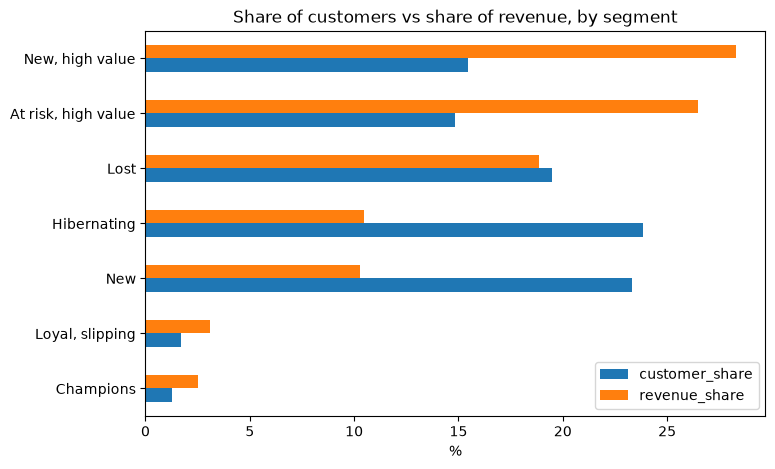

In [9]:
profile[['customer_share', 'revenue_share']].sort_values('revenue_share').plot(
    kind='barh', figsize=(8, 5))
plt.title('Share of customers vs share of revenue, by segment')
plt.xlabel('%')
plt.ylabel('')
plt.savefig(FIG + r"\s2_segments_share.png", dpi=150, bbox_inches='tight')
plt.show()

**Finding:** New, high value brings in the most revenue (28.3%) from 15.5% of customers.
The two "high value" segments together are 30.4% of customers but 54.8% of revenue.
Champions are only 1.3% of customers but 2.5% of revenue: each is worth about twice an average customer (median spend 235 BRL).
Hibernating is the largest segment (23.8% of customers) but brings in only 10.5% of revenue (median spend 69 BRL).

## Step 5. Experience by segment
Share of customers in each segment who had at least one late delivery and at least one bad (1 to 2 star) review.

In [10]:
delivered['is_bad'] = delivered['review_score'] <= 2

experience = delivered.groupby('customer_unique_id').agg(
    had_late=('is_late', 'max'),
    had_bad=('is_bad', 'max'),
    avg_score=('review_score', 'mean'),
)
experience.head()

,had_late,had_bad,avg_score
customer_unique_id,,,
0000366f3b9a7992bf8c76cfdf3221e2,False,False,5.0
0000b849f77a49e4a4ce2b2a4ca5be3f,False,False,4.0
0000f46a3911fa3c0805444483337064,False,False,3.0
0000f6ccb0745a6a4b88665a16c9f078,False,False,4.0
0004aac84e0df4da2b147fca70cf8255,False,False,5.0


In [11]:
rfm = rfm.join(experience)
rfm[['segment', 'had_late', 'had_bad', 'avg_score']].head()

,segment,had_late,had_bad,avg_score
customer_unique_id,,,,
0000366f3b9a7992bf8c76cfdf3221e2,"New, high value",False,False,5.0
0000b849f77a49e4a4ce2b2a4ca5be3f,New,False,False,4.0
0000f46a3911fa3c0805444483337064,Lost,False,False,3.0
0000f6ccb0745a6a4b88665a16c9f078,Hibernating,False,False,4.0
0004aac84e0df4da2b147fca70cf8255,"At risk, high value",False,False,5.0


In [12]:
exp_profile = rfm.groupby('segment').agg(
    customers=('segment', 'count'),
    late_share=('had_late', 'mean'),
    bad_share=('had_bad', 'mean'),
    avg_score=('avg_score', 'mean'),
)
exp_profile['late_share'] = exp_profile['late_share'] * 100
exp_profile['bad_share'] = exp_profile['bad_share'] * 100
exp_profile.sort_values('bad_share', ascending=False).round(1)

,customers,late_share,bad_share,avg_score
segment,,,,
"Loyal, slipping",1592,10.6,19.3,4.1
Champions,1209,11.1,18.3,4.3
"At risk, high value",13868,10.1,17.5,4.0
"New, high value",14442,6.8,14.0,4.1
Hibernating,22261,8.0,12.8,4.1
Lost,18208,3.6,10.9,4.2
New,21776,6.3,10.6,4.3


**Finding:** Bad experiences do not explain who stopped buying. Lost customers had the fewest late deliveries (3.6%) and few bad reviews (10.9%), so they left without a bad experience: nobody brought them back. This confirms EDA Q10: retention is a marketing gap, not a service problem.

Champions and Loyal customers show the highest bad-review shares (18 to 19%), but only because they placed more orders and so had more chances of one bad experience. Comparing only one-order segments is fairer.

Among one-order customers, the high-value segments had the most bad reviews (14.0% and 17.5%), in line with EDA Q8: expensive categories such as furniture and electronics disappoint more often.


In [13]:
print(rfm.groupby('R')['recency'].agg(['min', 'max']))
print(rfm.groupby('M')['monetary'].agg(['min', 'max']).round(0))

   min  max
R          
1  383  714
2  269  382
3  178  268
4   93  177
5    1   92
     min      max
M                
1    0.0     55.0
2   55.0     87.0
3   87.0    133.0
4  133.0    209.0
5  209.0  13664.0


In [14]:
by_cat = delivered.groupby('category')['customer_unique_id'].agg(['count', 'nunique'])
by_cat['orders_per_customer'] = by_cat['count'] / by_cat['nunique']
by_cat[by_cat['count'] >= 500].sort_values('orders_per_customer', ascending=False).head(10)

,count,nunique,orders_per_customer
category,,,
home_appliances,747,688,1.085756
fashion_bags_accessories,1811,1750,1.034857
bed_bath_table,9167,8912,1.028613
sports_leisure,7491,7304,1.025602
furniture_decor,6213,6091,1.020030
computers_accessories,6500,6375,1.019608
health_beauty,8609,8461,1.017492
watches_gifts,5470,5396,1.013714
pet_shop,1682,1661,1.012643


## Step 6. A reusable RFM toolkit
The steps above, rewritten as functions that work on any shop's orders.
Each function is tested against the Olist results.

### 6a. build_rfm: orders in, one row per customer out

In [15]:
def build_rfm(orders_df, customer_col, date_col, amount_col, order_col, ref_date=None):
    """One row per customer with recency (days), frequency (orders) and monetary (total spend)."""
    if ref_date is None:
        ref_date = orders_df[date_col].max() + pd.Timedelta(days=1)

    out = orders_df.groupby(customer_col).agg(
        last_order=(date_col, 'max'),
        frequency=(order_col, 'nunique'),
        monetary=(amount_col, 'sum'),
    )
    out['recency'] = (ref_date - out['last_order']).dt.days
    return out

In [16]:
test = build_rfm(delivered,
                 customer_col='customer_unique_id',
                 date_col='order_purchase_timestamp',
                 amount_col='total_paid',
                 order_col='order_id')

print(len(test), len(rfm))
print(test['recency'].median(), rfm['recency'].median())
print(test['monetary'].median().round(1), rfm['monetary'].median().round(1))

93356 93356
219.0 219.0
107.8 107.8


### 6b. score_rfm: add R, F and M scores
- R and M: equal groups (default 5), using ranks so ties never break the split.
- F: fixed groups you choose per market (default 1 order, 2 orders, 3+).

In [17]:
def score_rfm(rfm_df, n_groups=5, freq_bins=(0, 1, 2, float('inf'))):
    """Adds R, M (1 = worst, n_groups = best) and F (1 to len(freq_bins) - 1) scores."""
    out = rfm_df.copy()
    labels_up = list(range(1, n_groups + 1))

    out['R'] = pd.qcut(out['recency'].rank(method='first'), q=n_groups, labels=labels_up[::-1]).astype(int)
    out['M'] = pd.qcut(out['monetary'].rank(method='first'), q=n_groups, labels=labels_up).astype(int)

    f_labels = list(range(1, len(freq_bins)))
    out['F'] = pd.cut(out['frequency'], bins=list(freq_bins), labels=f_labels).astype(int)
    return out

In [18]:
test = score_rfm(test)

print(test[['R', 'F', 'M']].apply(pd.Series.value_counts).sort_index())
print('Same R as before:', (test['R'] == rfm['R']).mean().round(4))
print('Same M as before:', (test['M'] == rfm['M']).mean().round(4))
print('Same F as before:', (test['F'] == rfm['F']).mean().round(4))

       R        F      M
1  18671  90555.0  18672
2  18671   2573.0  18671
3  18671    228.0  18671
4  18671      NaN  18671
5  18672      NaN  18671
Same R as before: 0.9969
Same M as before: 0.9998
Same F as before: 1.0


**Test:** score_rfm reproduces the manual scores (F 100%, R 99.7%, M 99.98% identical). The small differences are customers with tied values at group borders, which ranking assigns consistently. Groups are now exactly equal in size.

### 6c. assign_segments: the rulebook, with adjustable cut-offs
- recent_min: lowest R score that counts as "recent" (default 4)
- value_min: lowest M score that counts as "high value" (default 4)
- repeat_min: lowest F score that counts as a repeat buyer (default 2)
- lost_max: highest R score that counts as "lost" (default 1)

In [19]:
def assign_segments(scored_df, recent_min=4, value_min=4, repeat_min=2, lost_max=1):
    """Adds a 'segment' column using adjustable R, F, M cut-offs."""
    def rule(row):
        if row['F'] >= repeat_min and row['R'] >= recent_min:
            return 'Champions'
        if row['F'] >= repeat_min:
            return 'Loyal, slipping'
        if row['R'] >= recent_min and row['M'] >= value_min:
            return 'New, high value'
        if row['R'] >= recent_min:
            return 'New'
        if row['R'] > lost_max and row['M'] >= value_min:
            return 'At risk, high value'
        if row['R'] > lost_max:
            return 'Hibernating'
        return 'Lost'

    out = scored_df.copy()
    out['segment'] = out.apply(rule, axis=1)
    return out

In [20]:
test = assign_segments(test)

compare = pd.DataFrame({
    'before': rfm['segment'].value_counts(),
    'now': test['segment'].value_counts(),
})
print(compare)
print('Same segment as before:', (test['segment'] == rfm['segment']).mean().round(4))

                     before    now
segment                           
Hibernating           22261  22283
New                   21776  21732
Lost                  18208  18235
New, high value       14442  14403
At risk, high value   13868  13902
Loyal, slipping        1592   1593
Champions              1209   1208
Same segment as before: 0.9988


In [21]:
strict = assign_segments(test, value_min=5)
strict['segment'].value_counts()

segment
Hibernating            29481
New                    29206
Lost                   18235
New, high value         6929
At risk, high value     6704
Loyal, slipping         1593
Champions               1208
Name: count, dtype: int64

**What this shows:** assign_segments reproduces the manual segments (99.88% identical) and turns the cut-offs into settings.
Raising value_min from 4 to 5 ("high value" = top 20% instead of top 40%) halves the high-value segments (about 28,000 to 13,600 customers); the rest move to New and Hibernating, while Lost, Loyal and Champions stay the same.
Where to draw the "high value" line is a business choice: a smaller group can get more personal, higher-cost treatment.

### 6d. profile_segments: size and value per segment

In [22]:
def profile_segments(segmented_df):
    """Size, value and recency per segment, sorted by revenue share."""
    p = segmented_df.groupby('segment').agg(
        customers=('segment', 'count'),
        revenue=('monetary', 'sum'),
        median_spend=('monetary', 'median'),
        median_recency=('recency', 'median'),
    )
    p['customer_share'] = p['customers'] / p['customers'].sum() * 100
    p['revenue_share'] = p['revenue'] / p['revenue'].sum() * 100
    return p.sort_values('revenue_share', ascending=False).round(1)

profile_segments(test)

,customers,revenue,median_spend,median_recency,customer_share,revenue_share
segment,,,,,,
"New, high value",14403,4352829.8,204.2,93.0,15.4,28.2
"At risk, high value",13902,4089444.7,205.0,268.0,14.9,26.5
Lost,18235,2916005.8,103.0,466.0,19.5,18.9
Hibernating,22283,1614249.8,69.3,268.0,23.9,10.5
New,21732,1584944.0,69.7,92.0,23.3,10.3
"Loyal, slipping",1593,475425.6,217.4,295.0,1.7,3.1
Champions,1208,388931.6,235.2,88.5,1.3,2.5


### 6e. Market playbooks
Marketing decisions per segment, kept separate from the data so the same toolkit works in any market.
Decisions: effort proportional to segment value; earn attention first, reward second; cross-sell rather than reorder reminders; 10 to 15% control group per segment.

In [23]:
BASE_PLAN = {
    'New, high value':     {'priority': 1, 'effort': 'Personal',      'step_1': 'Thank-you, care tips, cross-sell from their category', 'step_2': 'After 14 days with no order: free shipping'},
    'At risk, high value': {'priority': 1, 'effort': 'Personal',      'step_1': 'Check last experience; apology first if it was bad, then new arrivals in their category', 'step_2': 'After 14 days: 10% win-back offer'},
    'Champions':           {'priority': 2, 'effort': 'Personal',      'step_1': 'Early access and VIP perks, ask for a review', 'step_2': 'Loyalty reward on next order'},
    'Loyal, slipping':     {'priority': 2, 'effort': 'Semi-personal', 'step_1': '"We miss you" with cross-sell', 'step_2': 'After 14 days: free shipping'},
    'New':                 {'priority': 3, 'effort': 'Automated',     'step_1': 'Welcome series', 'step_2': 'Small incentive for order two'},
    'Hibernating':         {'priority': 3, 'effort': 'Automated',     'step_1': 'Seasonal reminders (Black Friday)', 'step_2': 'None'},
    'Lost':                {'priority': 4, 'effort': 'Automated',     'step_1': 'Big seasonal campaigns only', 'step_2': 'None'},
}

PLAYBOOKS = {
    'brazil': {
        'channels': {'Personal': 'Email + WhatsApp', 'Semi-personal': 'Email + WhatsApp', 'Automated': 'Email'},
        'retargeting': 'Meta (Facebook, Instagram)',
        'note': 'Offer boleto and installments on higher-priced items.',
    },
    'denmark': {
        'channels': {'Personal': 'Email + SMS', 'Semi-personal': 'Email', 'Automated': 'Email'},
        'retargeting': 'Meta (Facebook, Instagram)',
        'note': 'MobilePay at checkout; marketing email and SMS need consent; Trustpilot reviews are highly visible.',
    },
}

In [24]:
def build_action_plan(segmented_df, market, control_share=0.10):
    """Segment profile plus actions and channels for one market."""
    book = PLAYBOOKS[market]
    plan = profile_segments(segmented_df)

    plan['priority'] = plan.index.map(lambda s: BASE_PLAN[s]['priority'])
    plan['effort'] = plan.index.map(lambda s: BASE_PLAN[s]['effort'])
    plan['channel'] = plan['effort'].map(book['channels'])
    plan['step_1'] = plan.index.map(lambda s: BASE_PLAN[s]['step_1'])
    plan['step_2'] = plan.index.map(lambda s: BASE_PLAN[s]['step_2'])
    plan['control_group'] = (plan['customers'] * control_share).round().astype(int)

    print(f"Market: {market} | Retargeting: {book['retargeting']} | {book['note']}")
    return plan.sort_values(['priority', 'revenue_share'], ascending=[True, False])

In [25]:
build_action_plan(test, 'brazil')

Market: brazil | Retargeting: Meta (Facebook, Instagram) | Offer boleto and installments on higher-priced items.


,customers,revenue,median_spend,median_recency,customer_share,revenue_share,priority,effort,channel,step_1,step_2,control_group
segment,,,,,,,,,,,,
"New, high value",14403,4352829.8,204.2,93.0,15.4,28.2,1,Personal,Email + WhatsApp,"Thank-you, care tips, cross-sell from their ca...",After 14 days with no order: free shipping,1440
"At risk, high value",13902,4089444.7,205.0,268.0,14.9,26.5,1,Personal,Email + WhatsApp,Check last experience; apology first if it was...,After 14 days: 10% win-back offer,1390
"Loyal, slipping",1593,475425.6,217.4,295.0,1.7,3.1,2,Semi-personal,Email + WhatsApp,"""We miss you"" with cross-sell",After 14 days: free shipping,159
Champions,1208,388931.6,235.2,88.5,1.3,2.5,2,Personal,Email + WhatsApp,"Early access and VIP perks, ask for a review",Loyalty reward on next order,121
Hibernating,22283,1614249.8,69.3,268.0,23.9,10.5,3,Automated,Email,Seasonal reminders (Black Friday),None,2228
New,21732,1584944.0,69.7,92.0,23.3,10.3,3,Automated,Email,Welcome series,Small incentive for order two,2173
Lost,18235,2916005.8,103.0,466.0,19.5,18.9,4,Automated,Email,Big seasonal campaigns only,None,1824


In [26]:
build_action_plan(test, 'denmark', control_share=0.15)

Market: denmark | Retargeting: Meta (Facebook, Instagram) | MobilePay at checkout; marketing email and SMS need consent; Trustpilot reviews are highly visible.


,customers,revenue,median_spend,median_recency,customer_share,revenue_share,priority,effort,channel,step_1,step_2,control_group
segment,,,,,,,,,,,,
"New, high value",14403,4352829.8,204.2,93.0,15.4,28.2,1,Personal,Email + SMS,"Thank-you, care tips, cross-sell from their ca...",After 14 days with no order: free shipping,2160
"At risk, high value",13902,4089444.7,205.0,268.0,14.9,26.5,1,Personal,Email + SMS,Check last experience; apology first if it was...,After 14 days: 10% win-back offer,2085
"Loyal, slipping",1593,475425.6,217.4,295.0,1.7,3.1,2,Semi-personal,Email,"""We miss you"" with cross-sell",After 14 days: free shipping,239
Champions,1208,388931.6,235.2,88.5,1.3,2.5,2,Personal,Email + SMS,"Early access and VIP perks, ask for a review",Loyalty reward on next order,181
Hibernating,22283,1614249.8,69.3,268.0,23.9,10.5,3,Automated,Email,Seasonal reminders (Black Friday),None,3342
New,21732,1584944.0,69.7,92.0,23.3,10.3,3,Automated,Email,Welcome series,Small incentive for order two,3260
Lost,18235,2916005.8,103.0,466.0,19.5,18.9,4,Automated,Email,Big seasonal campaigns only,None,2735


### 6f. Using the toolkit as a module
The functions are saved in `src/rfm_toolkit.py`, so any notebook can import them.

In [27]:
import sys
sys.path.append(r"..\src")
import rfm_toolkit as rt

customers, plan = rt.run_rfm(
    delivered,
    customer_col='customer_unique_id',
    date_col='order_purchase_timestamp',
    amount_col='total_paid',
    order_col='order_id',
    market='denmark',
    value_min=5,
    control_share=0.15,
)
plan[['customers', 'revenue_share', 'effort', 'channel', 'control_group']]

Market: denmark | Retargeting: Meta (Facebook, Instagram) | MobilePay at checkout; marketing email and SMS need consent; Trustpilot reviews are highly visible.


,customers,revenue_share,effort,channel,control_group
segment,,,,,
"New, high value",6929,20.2,Personal,Email + SMS,1039
"At risk, high value",6704,18.8,Personal,Email + SMS,1006
"Loyal, slipping",1593,3.1,Semi-personal,Email,239
Champions,1208,2.5,Personal,Email + SMS,181
New,29206,18.3,Automated,Email,4381
Hibernating,29481,18.2,Automated,Email,4422
Lost,18235,18.9,Automated,Email,2735


### 6g. Save the final Olist outputs
Brazil playbook (the market of the data), default cut-offs (top 40% = recent / high value), 15% control group.

In [28]:
customers_br, plan_br = rt.run_rfm(
    delivered,
    customer_col='customer_unique_id',
    date_col='order_purchase_timestamp',
    amount_col='total_paid',
    order_col='order_id',
    market='brazil',
    control_share=0.15,
)

REPORTS = r"..\reports"
plan_br.to_csv(REPORTS + r"\segment_action_plan_brazil.csv")
customers_br.to_parquet(PROCESSED + r"\rfm_segments.parquet")
print('saved', plan_br.shape, customers_br.shape)

Market: brazil | Retargeting: Meta (Facebook, Instagram) | Offer boleto and installments on higher-priced items.
saved (7, 12) (93356, 8)


## Step 7. k-means clustering (unsupervised learning)
The RFM segments above were built with hand-written rules. k-means groups customers by similarity without any rules or labels; only the number of groups (k) is chosen.
Question: does the data find the same groups as the rules?
Preparation: spend is log-transformed (a few very large spenders would otherwise dominate) and all three features are scaled to the same range.

   k  inertia  silhouette
0  2   200512       0.687
1  3   136596       0.353
2  4    96102       0.363
3  5    80712       0.349
4  6    69658       0.338
5  7    60183       0.340
6  8    51597       0.357


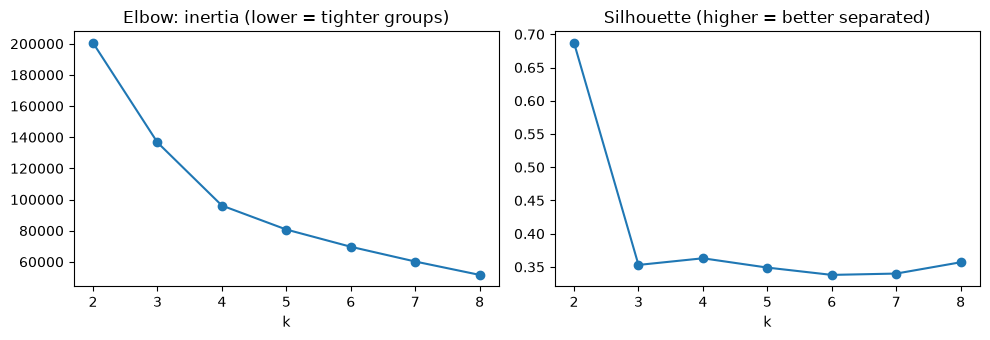

In [29]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rfm = pd.read_parquet(r"..\data\processed\rfm_segments.parquet")

features = pd.DataFrame({
    'recency': rfm['recency'],
    'frequency': rfm['frequency'],
    'log_monetary': np.log1p(rfm['monetary']),
})
X_km = StandardScaler().fit_transform(features)

scores = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_km)
    sil = silhouette_score(X_km, km.labels_, sample_size=10000, random_state=42)
    scores.append({'k': k, 'inertia': round(km.inertia_), 'silhouette': round(sil, 3)})
scores = pd.DataFrame(scores)
print(scores)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(scores['k'], scores['inertia'], marker='o'); axes[0].set_title('Elbow: inertia (lower = tighter groups)')
axes[1].plot(scores['k'], scores['silhouette'], marker='o'); axes[1].set_title('Silhouette (higher = better separated)')
for ax in axes: ax.set_xlabel('k')
plt.tight_layout(); plt.show()

**Choosing k.** k = 2 gives the highest silhouette (0.687), most likely because it only separates the 3% repeat buyers from one-time buyers (checked below). Among useful values, k = 4 is the elbow (inertia 200k → 96k, flattening after) and has the best silhouette (0.363).
A silhouette around 0.35 means weak to moderate structure: customers form a continuum rather than clearly separate groups, so where segment lines fall is partly a business choice.

In [30]:
# Check the k = 2 hypothesis
km2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit(X_km)
print(pd.crosstab(km2.labels_, rfm['frequency'] > 1, colnames=['repeat buyer']), "\n")

# Final: k = 4
km4 = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_km)
rfm['cluster'] = km4.labels_

profile = rfm.groupby('cluster').agg(
    customers=('cluster', 'size'),
    median_recency=('recency', 'median'),
    median_spend=('monetary', 'median'),
    repeat_pct=('frequency', lambda s: (s > 1).mean() * 100),
    revenue=('monetary', 'sum'),
)
profile['customer_pct'] = profile['customers'] / profile['customers'].sum() * 100
profile['revenue_pct'] = profile['revenue'] / profile['revenue'].sum() * 100
print(profile.drop(columns='revenue').round(1), "\n")

# How do clusters line up with the rule-based segments? (% of each segment per cluster)
(pd.crosstab(rfm['segment'], rfm['cluster'], normalize='index') * 100).round(0)

repeat buyer  False  True 
row_0                     
0                 0   2801
1             90555      0 

         customers  median_recency  median_spend  repeat_pct  customer_pct  \
cluster                                                                      
0             2801           199.0         225.6       100.0           3.0   
1            35706           147.0          66.0         0.0          38.2   
2            27000           418.0          98.1         0.0          28.9   
3            27849           170.0         210.4         0.0          29.8   

         revenue_pct  
cluster               
0                5.6  
1               16.0  
2               20.9  
3               57.5   



cluster,0,1,2,3
segment,,,,
"At risk, high value",0.0,0.0,15.0,85.0
Champions,100.0,0.0,0.0,0.0
Hibernating,0.0,64.0,33.0,3.0
Lost,0.0,0.0,96.0,4.0
"Loyal, slipping",100.0,0.0,0.0,0.0
New,0.0,98.0,0.0,2.0
"New, high value",0.0,1.0,0.0,99.0


**Result.** k = 2 only separates the 2,801 repeat buyers (a perfect split), confirming the hypothesis.
k = 4 gives four groups: repeat buyers (3.0% of customers, 5.6% of revenue), high spenders (29.8%, 57.5%), recent low spenders (38.2%, 16.0%) and lapsed customers (28.9%, 20.9%).
5 of 7 rule-based segments fall 85% or more into one cluster, so the rules reflect real structure.
The difference: k-means does not split high spenders by recency. Spend is the main divide in the data; the rules split new and slipping high spenders because they need different actions (cross-sell vs win-back). That split is justified by the action, not by the data's structure.
Decision: rule-based segments for action, k-means as validation.